# Region-Stratified Bivariate Spatial Cross-Correlation

**Aim 2 — Spatial co-localization within CT, IM, and Stroma regions**

Computes bivariate Moran's I within pathologist-annotated regions (CT, IM, Stroma)
for each sample. Reports both raw Moran's I and permutation-normalized z-scores
to enable fair cross-patient comparison despite variable region sizes.

Group comparisons use regression with log(spot count) as a covariate to
control for the confounding effect of region size on estimate precision.

In [1]:
import scanpy as sc
import numpy as np
import pandas as pd
import os
import warnings
from scipy.spatial import KDTree
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

# ============================================================
# CONFIGURATION
# ============================================================
SAMPLE_DIR = "/Users/adiallo/Desktop/Thesis/Data_Documents/All_Data/Visium_samples/Visium_Data/samples"
META_PATH = "/Users/adiallo/Desktop/Thesis/Data_Documents/data_all.csv"
OUTPUT_DIR = "/Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation/Region_Stratified"
ABUNDANCE_KEY = "means_cell_abundance_w_sf"
REGION_COL = "region"              # CT, IM, Stroma, Other
REGIONS_TO_ANALYZE = ["CT", "IM", "Stroma"]
MIN_SPOTS_PER_REGION = 50          # Skip regions with too few spots
N_PERMS = 999

os.makedirs(OUTPUT_DIR, exist_ok=True)

## Cell Type Pairs and Mappings

In [2]:
CELL_TYPE_PAIRS = [
    ("Tumor", "CD8"),
    ("Tumor", "Treg"),
    ("Tumor", "Macrophage"),
    ("Tumor", "CAF"),
    ("CAF", "CD8"),
    ("CAF", "Treg"),
    ("CAF", "Macrophage"),
    ("Tumor", "DC"),
]

BROAD_TO_C2L = {
    "Tumor":      ["Tumor"],
    "CD8":        ["cTNI10", "cTNI11", "cTNI12", "cTNI13", "cTNI14", "cTNI15", "cTNI16"],
    "CD4":        ["cTNI01", "cTNI02", "cTNI03", "cTNI04", "cTNI05", "cTNI06", "cTNI07"],
    "Treg":       ["cTNI08", "cTNI09"],
    "CAF":        ["cS27", "cS28", "cS29", "cS30", "cS31"],
    "Macrophage": ["cM01", "cM02"],
    "DC":         ["cM03", "cM04", "cM05", "cM06", "cM07", "cM08", "cM09"],
    "NK":         ["cTNI23", "cTNI24", "cTNI25"],
    "B_cell":     ["cB1", "cB2", "cB3"],
    "Fibroblast": ["cS21", "cS22", "cS23", "cS24", "cS25"],
}

## Helper Functions

Modified permutation test returns the full null distribution for z-score normalization.

In [3]:
def get_abundance_score(adata, broad_type):
    """Sum Cell2Location abundances for columns matching a broad cell type."""
    abund = adata.obsm[ABUNDANCE_KEY]
    patterns = BROAD_TO_C2L.get(broad_type, [])
    
    matching_cols = []
    for col in abund.columns:
        for pattern in patterns:
            clean = col.replace("meanscell_abundance_w_sf_", "").replace("means_cell_abundance_w_sf_", "")
            if clean.startswith(pattern) or pattern in clean:
                matching_cols.append(col)
                break
    
    if len(matching_cols) == 0:
        return None
    
    return abund[matching_cols].sum(axis=1).values


def spatial_weights_knn(coords, k=6):
    """Build row-normalized spatial weight matrix using k nearest neighbors."""
    tree = KDTree(coords)
    dists, indices = tree.query(coords, k=k+1)
    
    n = len(coords)
    W = np.zeros((n, n))
    for i in range(n):
        neighbors = indices[i, 1:]
        W[i, neighbors] = 1.0
    
    row_sums = W.sum(axis=1, keepdims=True)
    row_sums[row_sums == 0] = 1
    W = W / row_sums
    
    return W


def bivariate_morans_i(x, y, W):
    """Compute bivariate Moran's I between x and spatial lag of y."""
    n = len(x)
    zx = (x - x.mean()) / (x.std() + 1e-10)
    zy = (y - y.mean()) / (y.std() + 1e-10)
    Wy = W @ zy
    I = np.sum(zx * Wy) / n
    return I


def permutation_test_with_null(x, y, W, n_perms=999):
    """
    Permutation test returning observed I, p-value, and z-score.
    
    Stores the full null distribution to compute a z-score that
    normalizes for region size and weight matrix structure.
    """
    observed = bivariate_morans_i(x, y, W)
    
    null_dist = np.zeros(n_perms)
    for i in range(n_perms):
        y_perm = np.random.permutation(y)
        null_dist[i] = bivariate_morans_i(x, y_perm, W)
    
    # Two-sided p-value
    count = np.sum(np.abs(null_dist) >= np.abs(observed))
    p_value = (count + 1) / (n_perms + 1)
    
    # Z-score against permutation null
    null_mean = null_dist.mean()
    null_std = null_dist.std()
    if null_std > 1e-10:
        z_score = (observed - null_mean) / null_std
    else:
        z_score = 0.0
    
    return observed, p_value, z_score, null_mean, null_std

## Load Clinical Metadata

In [4]:
print("=" * 70)
print("REGION-STRATIFIED BIVARIATE SPATIAL CROSS-CORRELATION")
print("=" * 70)

clinical = pd.read_csv(META_PATH)
clinical.columns = clinical.columns.str.strip()
clinical["deident"] = clinical["deident"].astype(str)

def get_mets_group(row):
    """Three-level stratification: No_Mets / LN_Mets / Distant_Mets."""
    dm = str(row.get("Distant_Mets", "")).strip().upper()
    ln = str(row.get("ln_only", "")).strip().upper()
    if dm in ["T", "TRUE", "1", "YES"]:
        return "Distant_Mets"
    elif ln in ["T", "TRUE", "1", "YES"]:
        return "LN_Mets"
    else:
        return "No_Mets"

def get_mets_binary(row):
    """Two-level stratification matching Table 1."""
    am = str(row.get("any_mets", "")).strip().upper()
    if am in ["T", "TRUE", "1", "YES"]:
        return "Any_Mets"
    else:
        return "No_Mets"

clinical["mets_group"] = clinical.apply(get_mets_group, axis=1)
clinical["mets_binary"] = clinical.apply(get_mets_binary, axis=1)

# Verify on Visium subset
h5ad_files = [f for f in os.listdir(SAMPLE_DIR) if f.endswith(".h5ad")]
h5ad_files = [f for f in h5ad_files if f.replace('.h5ad', '').isdigit()]
visium_ids = [f.replace('.h5ad', '') for f in h5ad_files]

visium_clinical = clinical[clinical["deident"].isin(visium_ids)]
print(f"\nThree-group (Visium): {dict(visium_clinical['mets_group'].value_counts())}")
print(f"Two-group  (Visium): {dict(visium_clinical['mets_binary'].value_counts())}")
assert len(visium_ids) == 41, f"Expected 41 Visium samples, got {len(visium_ids)}"

REGION-STRATIFIED BIVARIATE SPATIAL CROSS-CORRELATION

Three-group (Visium): {'No_Mets': np.int64(19), 'LN_Mets': np.int64(12), 'Distant_Mets': np.int64(10)}
Two-group  (Visium): {'Any_Mets': np.int64(22), 'No_Mets': np.int64(19)}


## Compute Region-Stratified Bivariate Moran's I

For each sample, region (CT/IM/Stroma), and cell type pair:
- Subset spots to the region
- Build a new spatial weight matrix on the subsetted coordinates
- Run permutation test and compute z-score against the null

**Note:** This will take longer than the whole-tissue analysis due to 3× region splits.

In [5]:
RESULTS_CSV = os.path.join(OUTPUT_DIR, "region_bivariate_morans_i_results.csv")
RECOMPUTE = True  # Set False after first successful run

if not RECOMPUTE and os.path.exists(RESULTS_CSV):
    print("Loading precomputed region-stratified results from disk...")
    results_df = pd.read_csv(RESULTS_CSV)
    
    group_map = dict(zip(clinical["deident"], clinical["mets_group"]))
    binary_map = dict(zip(clinical["deident"], clinical["mets_binary"]))
    results_df["mets_group"] = results_df["sample_id"].astype(str).map(group_map)
    results_df["mets_binary"] = results_df["sample_id"].astype(str).map(binary_map)
    results_df.to_csv(RESULTS_CSV, index=False)
    
    print(f"Loaded {len(results_df)} measurements, mets groups reassigned.\n")
    print("-" * 70)
    for sid, sample_df in results_df.groupby("sample_id"):
        for region, reg_df in sample_df.groupby("region"):
            n_spots = reg_df["n_spots_region"].iloc[0]
            mg = reg_df["mets_group"].iloc[0]
            print(f"Sample {sid} | {region} ({n_spots} spots) [{mg}]")
            for _, row in reg_df.iterrows():
                sig_str = "*" if row["significant"] else " "
                print(f"    {row['type_a']}-{row['type_b']}: "
                      f"I={row['morans_I']:.4f}, z={row['z_score']:.2f}, "
                      f"p={row['p_value']:.3f} {sig_str}")

else:
    print("Computing region-stratified bivariate Moran's I...")
    print("-" * 70)

    results = []

    for h5ad_file in h5ad_files:
        sid = h5ad_file.replace(".h5ad", "")
        adata = sc.read_h5ad(os.path.join(SAMPLE_DIR, h5ad_file))

        # Get clinical info
        mets_row = clinical[clinical["deident"] == sid]
        mets_group = mets_row["mets_group"].values[0] if len(mets_row) > 0 else "Unknown"
        mets_binary = mets_row["mets_binary"].values[0] if len(mets_row) > 0 else "Unknown"

        # Check that region column exists
        if REGION_COL not in adata.obs.columns:
            print(f"Sample {sid}: '{REGION_COL}' column not found, skipping")
            continue

        print(f"\nSample {sid} ({adata.n_obs} total spots) [{mets_group}]")

        for region in REGIONS_TO_ANALYZE:
            # Subset to region
            region_mask = adata.obs[REGION_COL] == region
            n_region = region_mask.sum()

            if n_region < MIN_SPOTS_PER_REGION:
                print(f"  {region}: {n_region} spots (< {MIN_SPOTS_PER_REGION}), skipped")
                continue

            adata_region = adata[region_mask].copy()
            coords = adata_region.obsm["spatial"]

            # Build weight matrix on region-subsetted spots only
            k = min(6, n_region - 1)  # Guard against very small regions
            W = spatial_weights_knn(coords, k=k)

            print(f"  {region}: {n_region} spots")

            for type_a, type_b in CELL_TYPE_PAIRS:
                score_a = get_abundance_score(adata_region, type_a)
                score_b = get_abundance_score(adata_region, type_b)

                if score_a is None or score_b is None:
                    continue

                if score_a.std() < 1e-10 or score_b.std() < 1e-10:
                    continue

                I_val, p_val, z_score, null_mean, null_std = permutation_test_with_null(
                    score_a, score_b, W, n_perms=N_PERMS
                )

                results.append({
                    "sample_id": sid,
                    "region": region,
                    "type_a": type_a,
                    "type_b": type_b,
                    "pair": f"{type_a}\u2013{type_b}",
                    "morans_I": I_val,
                    "z_score": z_score,
                    "p_value": p_val,
                    "null_mean": null_mean,
                    "null_std": null_std,
                    "significant": p_val < 0.05,
                    "mets_group": mets_group,
                    "mets_binary": mets_binary,
                    "n_spots_region": n_region,
                    "n_spots_total": adata.n_obs,
                })

                sig_str = "*" if p_val < 0.05 else " "
                print(f"    {type_a}-{type_b}: I={I_val:.4f}, z={z_score:.2f}, p={p_val:.3f} {sig_str}")

    results_df = pd.DataFrame(results)
    results_df.to_csv(RESULTS_CSV, index=False)
    print(f"\nResults saved: {len(results_df)} measurements")

# Verify
print(f"\nSamples per region:")
print(results_df.groupby("region")["sample_id"].nunique())
print(f"\nSamples per mets_group:")
print(results_df.groupby("mets_group")["sample_id"].nunique())

Computing region-stratified bivariate Moran's I...
----------------------------------------------------------------------

Sample 40 (7217 total spots) [LN_Mets]
  CT: 3591 spots
    Tumor-CD8: I=0.3911, z=25.72, p=0.001 *
    Tumor-Treg: I=0.4403, z=28.26, p=0.001 *
    Tumor-Macrophage: I=-0.4009, z=-25.13, p=0.001 *
    Tumor-CAF: I=0.2618, z=16.15, p=0.001 *
    CAF-CD8: I=0.5554, z=36.16, p=0.001 *
    CAF-Treg: I=0.5390, z=34.78, p=0.001 *
    CAF-Macrophage: I=-0.0492, z=-3.02, p=0.003 *
    Tumor-DC: I=0.3770, z=23.33, p=0.001 *
  IM: 1319 spots
    Tumor-CD8: I=0.6980, z=27.40, p=0.001 *
    Tumor-Treg: I=0.7061, z=27.56, p=0.001 *
    Tumor-Macrophage: I=0.2856, z=11.18, p=0.001 *
    Tumor-CAF: I=0.7093, z=28.06, p=0.001 *
    CAF-CD8: I=0.6246, z=25.27, p=0.001 *
    CAF-Treg: I=0.6201, z=24.61, p=0.001 *
    CAF-Macrophage: I=0.4124, z=16.15, p=0.001 *
    Tumor-DC: I=0.7386, z=29.58, p=0.001 *
  Stroma: 2169 spots
    Tumor-CD8: I=0.6857, z=31.81, p=0.001 *
    Tumor-Treg

## Summary: Raw Moran's I and Z-Scores by Region

In [6]:
print(f"{'=' * 70}")
print("SUMMARY BY REGION")
print(f"{'=' * 70}")

for region in REGIONS_TO_ANALYZE:
    reg_df = results_df[results_df["region"] == region]
    if len(reg_df) == 0:
        continue
    print(f"\n{'─' * 50}")
    print(f"REGION: {region}  (median spots: {reg_df['n_spots_region'].median():.0f})")
    print(f"{'─' * 50}")
    
    for pair in reg_df["pair"].unique():
        sub = reg_df[reg_df["pair"] == pair]
        n_sig = sub["significant"].sum()
        print(f"  {pair}:")
        print(f"    Raw I:   mean={sub['morans_I'].mean():.4f}, "
              f"median={sub['morans_I'].median():.4f}")
        print(f"    Z-score: mean={sub['z_score'].mean():.2f}, "
              f"median={sub['z_score'].median():.2f}")
        print(f"    Significant: {n_sig}/{len(sub)} samples")
        
        for mg in ["No_Mets", "LN_Mets", "Distant_Mets"]:
            mg_sub = sub[sub["mets_group"] == mg]
            if len(mg_sub) > 0:
                print(f"      {mg}: I={mg_sub['morans_I'].mean():.4f}, "
                      f"z={mg_sub['z_score'].mean():.2f} (n={len(mg_sub)})")

SUMMARY BY REGION

──────────────────────────────────────────────────
REGION: CT  (median spots: 3591)
──────────────────────────────────────────────────
  Tumor–CD8:
    Raw I:   mean=0.3650, median=0.4307
    Z-score: mean=21.79, median=25.44
    Significant: 37/41 samples
      No_Mets: I=0.3801, z=20.59 (n=19)
      LN_Mets: I=0.2977, z=17.49 (n=12)
      Distant_Mets: I=0.4170, z=29.25 (n=10)
  Tumor–Treg:
    Raw I:   mean=0.4092, median=0.4546
    Z-score: mean=25.30, median=27.00
    Significant: 39/41 samples
      No_Mets: I=0.4114, z=23.52 (n=19)
      LN_Mets: I=0.3670, z=22.61 (n=12)
      Distant_Mets: I=0.4554, z=31.91 (n=10)
  Tumor–Macrophage:
    Raw I:   mean=-0.0784, median=-0.1137
    Z-score: mean=-6.36, median=-6.49
    Significant: 37/41 samples
      No_Mets: I=-0.0553, z=-5.79 (n=19)
      LN_Mets: I=-0.1922, z=-12.20 (n=12)
      Distant_Mets: I=0.0145, z=-0.45 (n=10)
  Tumor–CAF:
    Raw I:   mean=-0.1146, median=-0.1741
    Z-score: mean=-9.25, median=-10.4

## Group Comparisons with Spot-Count Adjustment

For each region and cell type pair, compare z-scores across metastasis groups
using OLS regression with log(spot count) as a covariate.

Also runs unadjusted Kruskal-Wallis and Mann-Whitney for comparison.

In [7]:
print(f"{'=' * 70}")
print("GROUP COMPARISONS — Z-SCORES WITH SPOT-COUNT ADJUSTMENT")
print(f"{'=' * 70}")

stat_results = []

for region in REGIONS_TO_ANALYZE:
    reg_df = results_df[results_df["region"] == region].copy()
    if len(reg_df) == 0:
        continue
    
    print(f"\n{'─' * 50}")
    print(f"REGION: {region}")
    print(f"{'─' * 50}")
    
    for pair in reg_df["pair"].unique():
        sub = reg_df[reg_df["pair"] == pair].copy()
        sub["log_n_spots"] = np.log(sub["n_spots_region"])
        
        # ---- Three-group: Kruskal-Wallis on z-scores ----
        groups_3 = {}
        for mg in ["No_Mets", "LN_Mets", "Distant_Mets"]:
            vals = sub[sub["mets_group"] == mg]["z_score"].values
            if len(vals) >= 2:
                groups_3[mg] = vals
        
        if len(groups_3) >= 2:
            kw_stat, kw_p = stats.kruskal(*groups_3.values())
            print(f"\n  {pair}")
            print(f"    KW (3-group, z-scores): H={kw_stat:.3f}, p={kw_p:.4f}")
            stat_results.append({
                "region": region, "pair": pair,
                "test": "KW_3group_zscore",
                "statistic": kw_stat, "p_value": kw_p,
            })
            
            # Pairwise
            for g1, g2 in [("Distant_Mets", "No_Mets"), ("LN_Mets", "No_Mets"),
                           ("Distant_Mets", "LN_Mets")]:
                if g1 in groups_3 and g2 in groups_3:
                    u_stat, u_p = stats.mannwhitneyu(
                        groups_3[g1], groups_3[g2], alternative="two-sided"
                    )
                    print(f"      {g1} vs {g2}: U={u_stat:.1f}, p={u_p:.4f}")
                    stat_results.append({
                        "region": region, "pair": pair,
                        "test": f"{g1}_vs_{g2}_zscore",
                        "statistic": u_stat, "p_value": u_p,
                    })
        
        # ---- OLS: z-score ~ mets_group + log(n_spots) ----
        if len(groups_3) >= 2 and len(sub) >= 10:
            try:
                model = smf.ols(
                    "z_score ~ C(mets_group, Treatment(reference='No_Mets')) + log_n_spots",
                    data=sub
                ).fit()
                
                print(f"    OLS (adjusted for log spot count):")
                for param in model.params.index:
                    if "mets_group" in param or param == "log_n_spots":
                        coef = model.params[param]
                        pval = model.pvalues[param]
                        label = param.replace("C(mets_group, Treatment(reference='No_Mets'))", "")
                        label = label.replace("[T.", "").replace("]", "")
                        print(f"      {label}: coef={coef:.3f}, p={pval:.4f}")
                
                stat_results.append({
                    "region": region, "pair": pair,
                    "test": "OLS_adjusted",
                    "statistic": model.fvalue,
                    "p_value": model.f_pvalue,
                })
            except Exception as e:
                print(f"    OLS failed: {e}")
        
        # ---- Two-group: Mann-Whitney on z-scores ----
        any_vals = sub[sub["mets_binary"] == "Any_Mets"]["z_score"].values
        no_vals = sub[sub["mets_binary"] == "No_Mets"]["z_score"].values
        
        if len(any_vals) >= 2 and len(no_vals) >= 2:
            u_stat, u_p = stats.mannwhitneyu(any_vals, no_vals, alternative="two-sided")
            print(f"    MW (2-group, z-scores): U={u_stat:.1f}, p={u_p:.4f}")
            stat_results.append({
                "region": region, "pair": pair,
                "test": "MW_2group_zscore",
                "statistic": u_stat, "p_value": u_p,
            })

stat_df = pd.DataFrame(stat_results)
stat_df.to_csv(os.path.join(OUTPUT_DIR, "region_group_statistics.csv"), index=False)
print(f"\nStatistics saved.")

GROUP COMPARISONS — Z-SCORES WITH SPOT-COUNT ADJUSTMENT

──────────────────────────────────────────────────
REGION: CT
──────────────────────────────────────────────────

  Tumor–CD8
    KW (3-group, z-scores): H=3.767, p=0.1520
      Distant_Mets vs No_Mets: U=128.0, p=0.1359
      LN_Mets vs No_Mets: U=96.0, p=0.4779
      Distant_Mets vs LN_Mets: U=87.0, p=0.0806
    OLS (adjusted for log spot count):
      Distant_Mets: coef=8.083, p=0.2703
      LN_Mets: coef=-3.134, p=0.6386
      log_n_spots: coef=1.204, p=0.7427
    MW (2-group, z-scores): U=224.0, p=0.7046

  Tumor–Treg
    KW (3-group, z-scores): H=2.397, p=0.3016
      Distant_Mets vs No_Mets: U=124.0, p=0.1910
      LN_Mets vs No_Mets: U=116.0, p=0.9515
      Distant_Mets vs LN_Mets: U=82.0, p=0.1563
    OLS (adjusted for log spot count):
      Distant_Mets: coef=6.442, p=0.3795
      LN_Mets: coef=-1.052, p=0.8748
      log_n_spots: coef=4.082, p=0.2707
    MW (2-group, z-scores): U=240.0, p=0.4252

  Tumor–Macrophage
    

## Boxplots: Z-Scores by Region and Mets Group

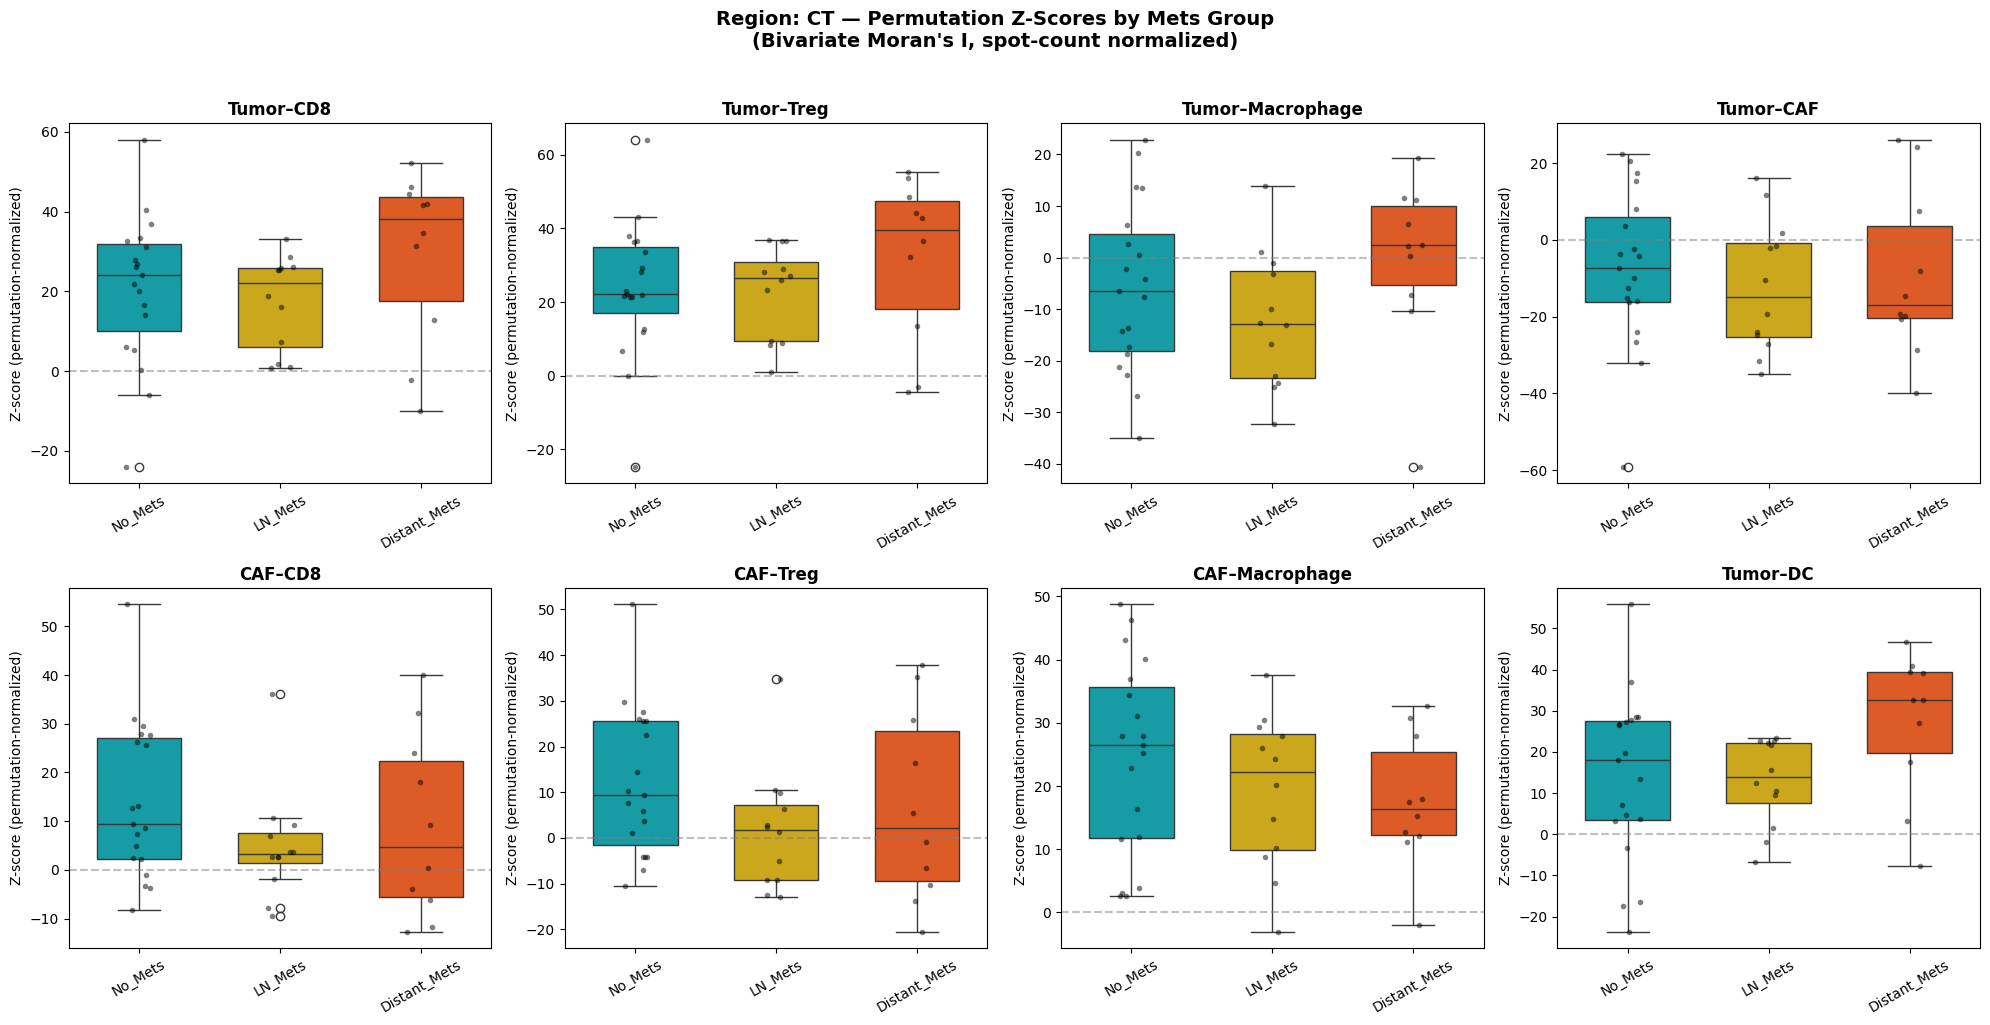

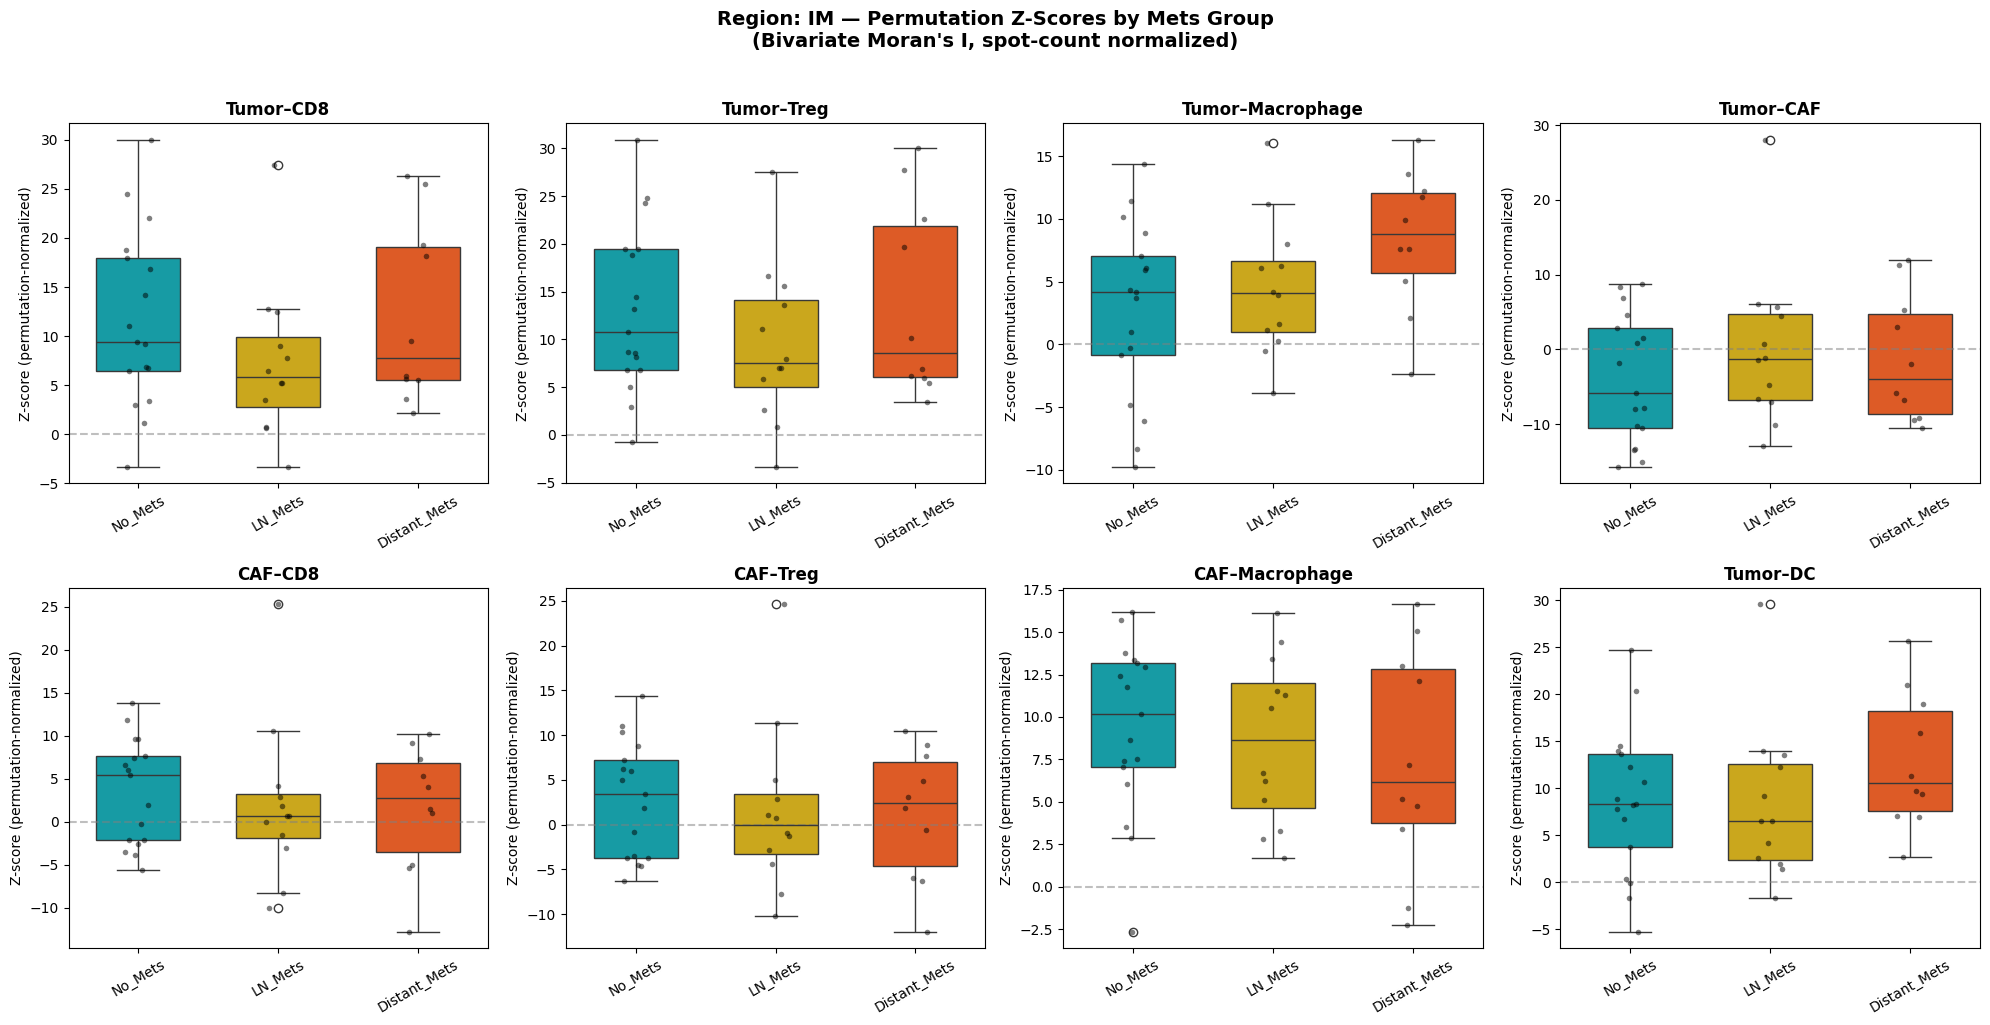

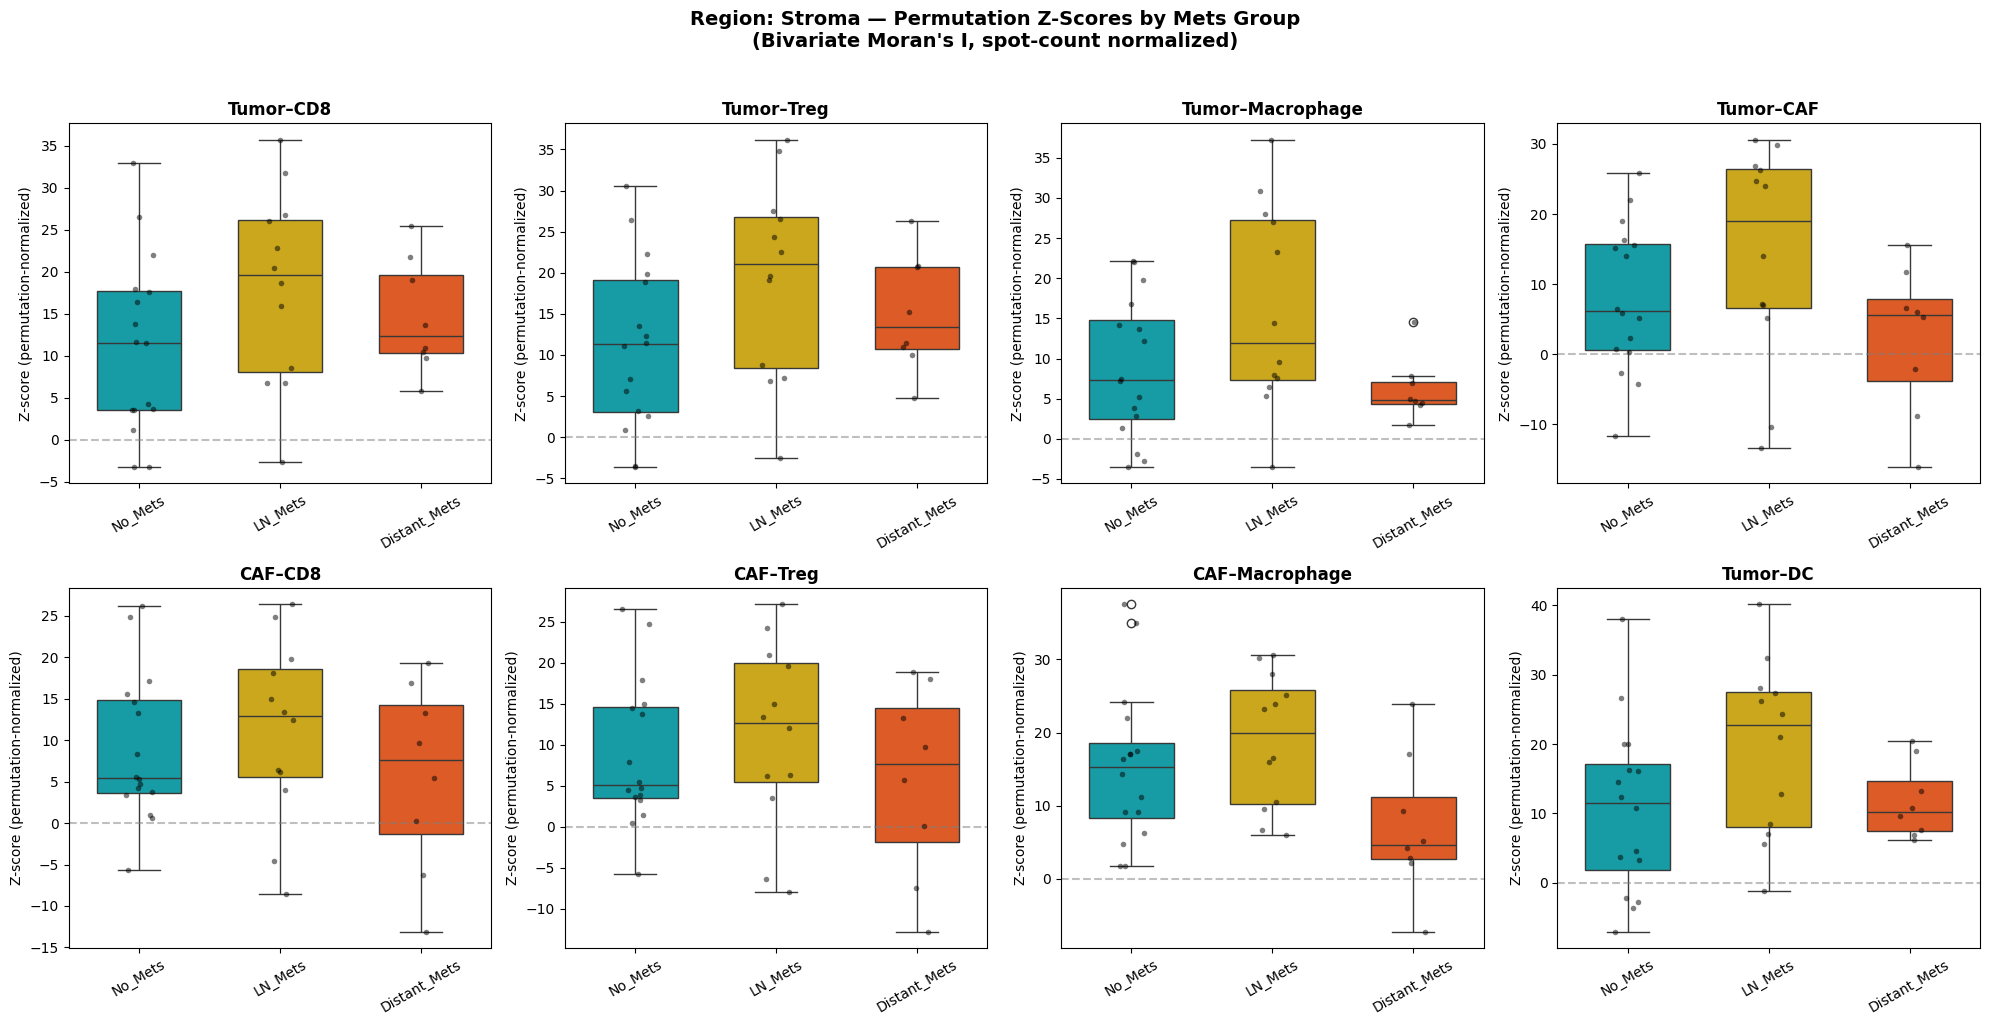

Plots saved to /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation/Region_Stratified


In [8]:
METS_ORDER_3 = ["No_Mets", "LN_Mets", "Distant_Mets"]
METS_PALETTE_3 = {"No_Mets": "#00AFBB", "LN_Mets": "#E7B800", "Distant_Mets": "#FC4E07"}

for region in REGIONS_TO_ANALYZE:
    reg_df = results_df[results_df["region"] == region]
    if len(reg_df) == 0:
        continue
    
    pairs_to_plot = reg_df["pair"].unique()
    n_pairs = len(pairs_to_plot)
    n_cols = 4
    n_rows = int(np.ceil(n_pairs / n_cols))
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 5 * n_rows), facecolor="white")
    axes = axes.flatten() if n_pairs > 1 else [axes]
    
    for idx, pair in enumerate(pairs_to_plot):
        ax = axes[idx]
        sub = reg_df[reg_df["pair"] == pair]
        
        sns.boxplot(data=sub, x="mets_group", y="z_score", order=METS_ORDER_3,
                    palette=METS_PALETTE_3, ax=ax, width=0.6)
        sns.stripplot(data=sub, x="mets_group", y="z_score", order=METS_ORDER_3,
                      color="black", alpha=0.5, size=4, ax=ax)
        
        ax.set_title(pair, fontsize=12, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("Z-score (permutation-normalized)")
        ax.axhline(y=0, color="grey", linestyle="--", alpha=0.5)
        ax.tick_params(axis="x", rotation=30)
    
    for idx in range(len(pairs_to_plot), len(axes)):
        axes[idx].set_visible(False)
    
    plt.suptitle(f"Region: {region} \u2014 Permutation Z-Scores by Mets Group\n"
                 f"(Bivariate Moran's I, spot-count normalized)",
                 fontsize=14, fontweight="bold", y=1.02)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"zscore_boxplots_{region}_3group.png"),
                dpi=200, bbox_inches="tight")
    plt.show()

print(f"Plots saved to {OUTPUT_DIR}")

## Heatmaps: Z-Scores by Region, Pair, and Mets Group

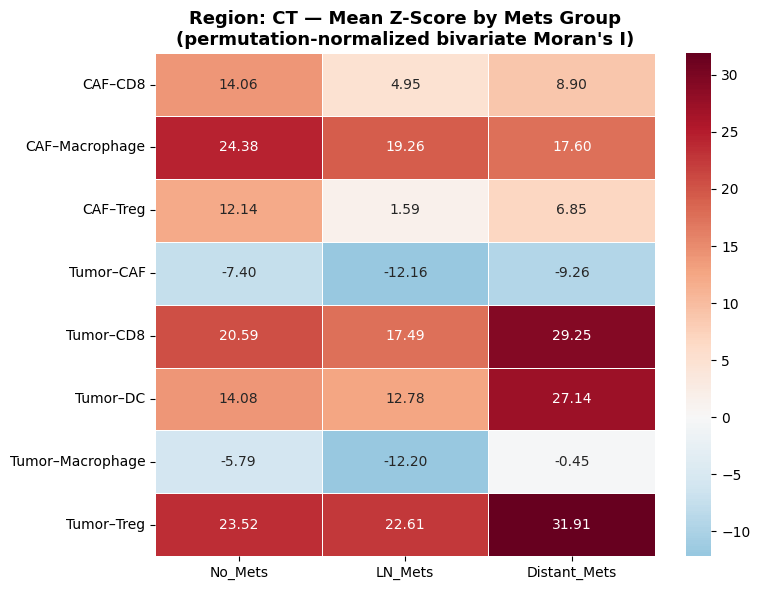

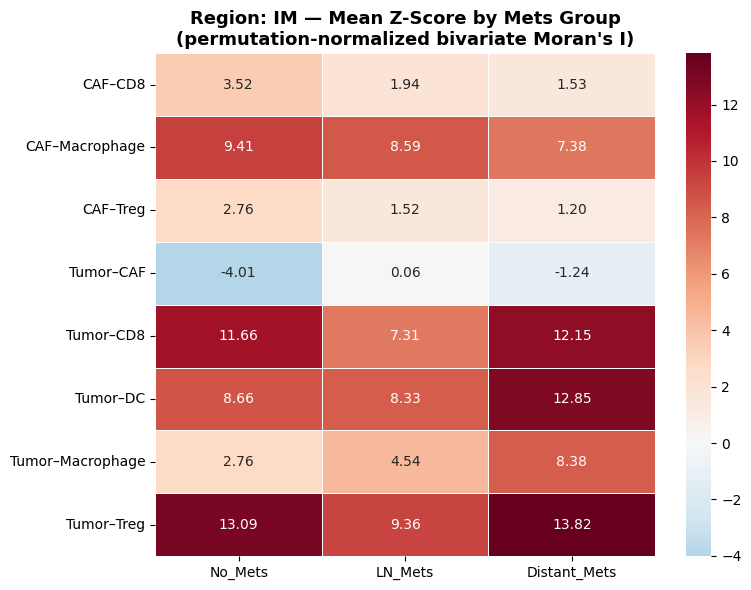

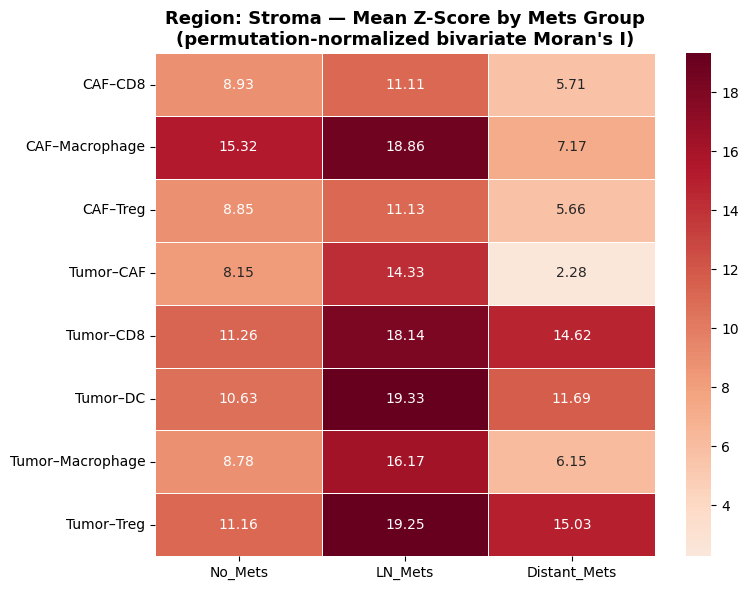


All results saved to /Users/adiallo/Desktop/Thesis/Results/AIM_2_Results/Spatial_CrossCorrelation/Region_Stratified
Done!


In [9]:
for region in REGIONS_TO_ANALYZE:
    reg_df = results_df[results_df["region"] == region]
    if len(reg_df) == 0:
        continue
    
    pivot = reg_df.pivot_table(
        index="pair", columns="mets_group", values="z_score", aggfunc="mean"
    )
    pivot = pivot.reindex(columns=METS_ORDER_3)
    
    fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
    sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax,
                linewidths=0.5, linecolor="white")
    ax.set_title(f"Region: {region} \u2014 Mean Z-Score by Mets Group\n"
                 f"(permutation-normalized bivariate Moran's I)",
                 fontsize=13, fontweight="bold")
    ax.set_ylabel("")
    ax.set_xlabel("")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"zscore_heatmap_{region}_3group.png"),
                dpi=200, bbox_inches="tight")
    plt.show()

print(f"\nAll results saved to {OUTPUT_DIR}")
print("Done!")

## Cross-Region Comparison

For each cell type pair, compare z-scores across regions (CT vs IM vs Stroma)
to test whether co-localization patterns shift between compartments.

In [10]:
print(f"{'=' * 70}")
print("CROSS-REGION COMPARISON (CT vs IM vs Stroma)")
print(f"{'=' * 70}")

cross_region_stats = []

for pair in results_df["pair"].unique():
    sub = results_df[results_df["pair"] == pair]
    
    # Need paired data — same samples across regions
    # Use samples that have all three regions
    sample_region_counts = sub.groupby("sample_id")["region"].nunique()
    complete_samples = sample_region_counts[sample_region_counts == 3].index
    sub_complete = sub[sub["sample_id"].isin(complete_samples)]
    
    if len(complete_samples) < 5:
        print(f"\n  {pair}: only {len(complete_samples)} samples with all 3 regions, skipped")
        continue
    
    region_groups = {}
    for region in REGIONS_TO_ANALYZE:
        vals = sub_complete[sub_complete["region"] == region]["z_score"].values
        if len(vals) >= 2:
            region_groups[region] = vals
    
    if len(region_groups) >= 2:
        # Friedman test (paired non-parametric) if all three regions present
        if len(region_groups) == 3:
            # Align by sample
            pivot_paired = sub_complete.pivot_table(
                index="sample_id", columns="region", values="z_score"
            ).dropna()
            
            if len(pivot_paired) >= 5:
                fr_stat, fr_p = stats.friedmanchisquare(
                    pivot_paired["CT"].values,
                    pivot_paired["IM"].values,
                    pivot_paired["Stroma"].values
                )
                print(f"\n  {pair} (n={len(pivot_paired)} paired samples):")
                print(f"    Friedman: chi2={fr_stat:.3f}, p={fr_p:.4f}")
                cross_region_stats.append({
                    "pair": pair, "test": "Friedman_3region",
                    "statistic": fr_stat, "p_value": fr_p,
                    "n_samples": len(pivot_paired),
                })
                
                # Pairwise Wilcoxon signed-rank
                for r1, r2 in [("CT", "IM"), ("CT", "Stroma"), ("IM", "Stroma")]:
                    w_stat, w_p = stats.wilcoxon(pivot_paired[r1], pivot_paired[r2])
                    print(f"      {r1} vs {r2}: W={w_stat:.1f}, p={w_p:.4f}")
                    cross_region_stats.append({
                        "pair": pair, "test": f"{r1}_vs_{r2}",
                        "statistic": w_stat, "p_value": w_p,
                        "n_samples": len(pivot_paired),
                    })
                
                # Print region means
                for r in REGIONS_TO_ANALYZE:
                    print(f"      {r}: mean z={pivot_paired[r].mean():.2f}")

cross_region_df = pd.DataFrame(cross_region_stats)
cross_region_df.to_csv(os.path.join(OUTPUT_DIR, "cross_region_statistics.csv"), index=False)
print(f"\nCross-region statistics saved.")

CROSS-REGION COMPARISON (CT vs IM vs Stroma)

  Tumor–CD8 (n=36 paired samples):
    Friedman: chi2=7.722, p=0.0210
      CT vs IM: W=121.0, p=0.0005
      CT vs Stroma: W=226.0, p=0.0946
      IM vs Stroma: W=229.0, p=0.1045
      CT: mean z=20.28
      IM: mean z=10.70
      Stroma: mean z=14.30

  Tumor–Treg (n=36 paired samples):
    Friedman: chi2=13.389, p=0.0012
      CT vs IM: W=97.0, p=0.0001
      CT vs Stroma: W=186.0, p=0.0201
      IM vs Stroma: W=265.0, p=0.2928
      CT: mean z=23.37
      IM: mean z=12.47
      Stroma: mean z=14.71

  Tumor–Macrophage (n=36 paired samples):
    Friedman: chi2=19.056, p=0.0001
      CT vs IM: W=107.0, p=0.0002
      CT vs Stroma: W=70.0, p=0.0000
      IM vs Stroma: W=145.0, p=0.0025
      CT: mean z=-6.59
      IM: mean z=4.63
      Stroma: mean z=10.66

  Tumor–CAF (n=36 paired samples):
    Friedman: chi2=17.556, p=0.0002
      CT vs IM: W=226.0, p=0.0946
      CT vs Stroma: W=101.0, p=0.0001
      IM vs Stroma: W=78.0, p=0.0000
     